## Model výberu portfólia v priestore očakávaný výnos – CVaR

V tejto časti práce konštruujeme model výberu portfólia, v ktorom je mierou rizika
**Conditional Value at Risk (CVaR)**. Ako vstupné údaje používame týždenné výnosy
desiatich vybraných akcií z databázy Yahoo Finance za obdobie od 30. 9. 2020
do 30. 9. 2025.

In [2]:
import numpy as np
from mip import Model, xsum, minimize
from numpy import mean
import yfinance
import matplotlib.pyplot as plt #grafy
import pandas as pd
# --- 1. Dáta z Yahoo Finance ---
df = {}
tickers = ["NVDA","MSFT","AAPL","GOOGL","AMZN",
           "ANET","GE","JPM","INTC","FDX"]

df = yfinance.download(tickers,
                       start="2020-09-30",
                       end="2025-09-30",
                       auto_adjust=False)

# týždenné výnosy Adjusted Close
assets_weekly_returns = df['Adj Close'].resample('W').ffill().pct_change()
print("Týždenne vynosy:")
print(assets_weekly_returns.head())

# vynecháme prvý riadok (NaN) a prekonvertujeme na numpy
vstup = assets_weekly_returns[1:].to_numpy()

# kontrola, či nie sú chýbajúce údaje
if np.isnan(vstup).any():
    print("Nie su dostupne vsetky data")

# tt = počet období (týždňov), T = množina indexov období
tt, T = len(vstup), set(range(len(vstup)))
# jj = počet aktív, N = množina indexov aktív
jj, N = len(vstup[0]), set(range(len(vstup[0])))

[*********************100%***********************]  10 of 10 completed

Týždenne vynosy:
Ticker          AAPL      AMZN      ANET       FDX        GE     GOOGL  \
Date                                                                     
2020-10-04       NaN       NaN       NaN       NaN       NaN       NaN   
2020-10-11  0.034949  0.051728  0.116283  0.064067  0.070422  0.037682   
2020-10-18  0.017526 -0.004241 -0.009490  0.045369  0.065790  0.037903   
2020-10-25 -0.033440 -0.020873 -0.050299 -0.001092  0.046639  0.041641   
2020-11-01 -0.053720 -0.052506 -0.024333 -0.084956 -0.027523 -0.010331   

Ticker          INTC       JPM      MSFT      NVDA  
Date                                                
2020-10-04       NaN       NaN       NaN       NaN  
2020-10-11  0.035483  0.043407  0.046656  0.053628  
2020-10-18  0.025369  0.003063  0.017840  0.003542  
2020-10-25 -0.110044  0.022658 -0.015615 -0.016020  
2020-11-01 -0.081328 -0.055582 -0.063636 -0.077721  


### Výpočet očakávaných výnosov akcií

Na základe historických týždenných výnosov vypočítame priemerný (očakávaný)
týždenný výnos pre každé aktívum. Tieto hodnoty slúžia ako vstup pre podmienku
minimálneho požadovaného výnosu portfólia $Ep$ v optimalizačnom modeli CVaR.


In [3]:
# --- 2. Očakávané výnosy jednotlivých akcií ---
E = {}
for j in N:
    E[j] = mean(vstup[:, j])

print("Ocakavany vynos (priemy tyzdenny vynos):")
for j in N:
    print(f"{tickers[j]}: {E[j]:.6f}", end=', ')
print("\n")

# nastavíme interval cieľových výnosov podľa min a max z E
Epmin = min(E[j] for j in N)
Epmax = max(E[j] for j in N)

print(f"Epmin = {Epmin:.6f}, Epmax = {Epmax:.6f}")

# hladina spoľahlivosti pre CVaR
alfa = 0.05

Ocakavany vynos (priemy tyzdenny vynos):
NVDA: 0.003942, MSFT: 0.002340, AAPL: 0.011283, GOOGL: 0.001042, AMZN: 0.009604, ANET: 0.005574, GE: 0.000859, JPM: 0.005655, INTC: 0.004237, FDX: 0.012407, 

Epmin = 0.000859, Epmax = 0.012407


Na základe týchto hodnôt priemerných výnosov bol určený interval cieľových výnosov portfólia od $Epmin = 0.000859$ po $Epmax = 0.012407$, ktorý predstavuje minimálny a maximálny priemerný výnos dostupný v rámci sledovaných akcií. 

### Modelovanie a výpočet portfólií podľa CVaR

V ďalšom kroku konštruujeme hranicu portfólií v priestore očakávaný výnos – $CVaR$.
Pre 20 rôznych úrovní cieľového výnosu $Ep$ postupne riešime optimalizačný model,
ktorý minimalizuje riziko merané pomocou Conditional Value at Risk.

In [4]:
# --- 3. Výpočet 20 portfólií na CVaR hranici ---
Ep_zoznam = []        # cieľové očakávané výnosy
ExpReturn_zoznam = [] # skutočný očakávaný výnos portfólia
CVaR_zoznam = []      # hodnota CVaR z objektívu
W_zoznam = []         # váhy portfólií

for i in range(20):
    # 20 rovnomerne rozložených cieľových výnosov v intervale <Epmin, Epmax>
    Ep = Epmin + (Epmax - Epmin) * i / 19
    Ep_zoznam.append(Ep)

    m = Model()  # default = minimize

    # váhy portfólia (long-only)
    w = [m.add_var(name=f'w_{j}', var_type="C", lb=0) for j in N]
    # pomocné premenné pre CVaR
    z = [m.add_var(name=f'z_{t}', var_type="C", lb=0) for t in T]
    # VaR premenná
    VaR = m.add_var(name='VaR', var_type="C")

    # cieľ: minimalizovať CVaR = VaR + (1/(alfa*tt)) * sum(z_t)
    m.objective = minimize(
        VaR + (xsum(z[t] for t in T) / (alfa * tt))
    )

    # CVaR obmedzenia: z_t + r_p,t + VaR >= 0
    for t in T:
        m += z[t] + xsum(vstup[t, j] * w[j] for j in N) + VaR >= 0

    # obmedzenie na očakávaný výnos portfólia: sum E_j * w_j >= Ep
    m += xsum(E[j] * w[j] for j in N) >= Ep

    # súčet váh = 1
    m += xsum(w[j] for j in N) == 1

    # optimalizácia
    m.optimize()

    # získame váhy
    vahy = np.array([w[j].x for j in N])
    # skutočný očakávaný výnos portfólia
    ExpReturn = float(sum(E[j] * vahy[j] for j in N))
    # hodnota CVaR z objektívnej funkcie
    CVaR_hodnota = float(m.objective_value)

    ExpReturn_zoznam.append(ExpReturn)
    CVaR_zoznam.append(CVaR_hodnota)
    W_zoznam.append(vahy)




### Výsledné portólia (CVaR)

Uvedená tabuľka zobrazuje 20 portfolií získaných pomocou optimalizačného modelu. Každý riadok tabulky predstavuje jedno portfólio,
určené pre konkrétnu úroveň cieľového očakávaného výnosu $Ep$.
Súčasťou tabuľky je:

- požadované cieľové výnosy,
- skutočný očakávaný výnos portfólia,
- hodnotu rizika CVaR pri hladine spoľahlivosti $\alpha = 5\%$,
- váhy jednotlivých akcií.


In [5]:
# --- 4. tabuľka portfólií ---

# základná tabuľka: ID, cieľový výnos, skutočný výnos, CVaR
tabulka = pd.DataFrame({
    "ID_portfolia": range(1, len(Ep_zoznam) + 1),
    "Ep": Ep_zoznam,
    "ExpReturn": ExpReturn_zoznam,
    "CVaR": CVaR_zoznam
})

# pridáme váhy pre jednotlivé akcie
for idx, ticker in enumerate(tickers):
    tabulka[f"w_{ticker}"] = [W_zoznam[i][idx] for i in range(len(W_zoznam))]

# zaokrúhlenie pre krajší výstup
tabulka["Ep"] = tabulka["Ep"].round(6)
tabulka["ExpReturn"] = tabulka["ExpReturn"].round(6)
tabulka["CVaR"] = tabulka["CVaR"].round(6)

for ticker in tickers:
    tabulka[f"w_{ticker}"] = tabulka[f"w_{ticker}"].round(4)

print(tabulka)

tabulka.to_csv("tabulka_portfolii.csv", index=False, encoding="utf-8")


    ID_portfolia        Ep  ExpReturn      CVaR  w_NVDA  w_MSFT  w_AAPL  \
0              1  0.000859   0.005217  0.051401  0.0564     0.0  0.0706   
1              2  0.001467   0.005217  0.051401  0.0564     0.0  0.0706   
2              3  0.002075   0.005217  0.051401  0.0564     0.0  0.0706   
3              4  0.002683   0.005217  0.051401  0.0564     0.0  0.0706   
4              5  0.003290   0.005217  0.051401  0.0564     0.0  0.0706   
5              6  0.003898   0.005217  0.051401  0.0564     0.0  0.0706   
6              7  0.004506   0.005217  0.051401  0.0564     0.0  0.0706   
7              8  0.005114   0.005217  0.051401  0.0564     0.0  0.0706   
8              9  0.005722   0.005722  0.052357  0.0815     0.0  0.0835   
9             10  0.006329   0.006329  0.054021  0.0000     0.0  0.1210   
10            11  0.006937   0.006937  0.056277  0.0000     0.0  0.2056   
11            12  0.007545   0.007545  0.059378  0.0000     0.0  0.2987   
12            13  0.00815

### Interpretácia výsledných portfólií (CVaR)

Z tabuľky vidno, že pri raste cieľového výnosu \(Ep\) sa postupne zvyšuje aj riziko
merané pomocou CVaR.

**Portfólia s minimálym rizkom (ID 1–7)**  
  Majú rovnakú hodnotu $CVaR ≈ 0{,}0514$ a očakávaný výnos  
  $ \text{ExpReturn} \approx 0{,}0052 $.  
  Portfólio je rozložené medzi viacero akcií – menší podiel NVDA a AAPL,
  významnejší podiel ANET, JPM a INTC. Ide o konzervatívne riešenia
  s nízkym rizikom strát.


**Portfólio s maximálnym výnosom (ID 20)**  
  Dosahujú najvyšší výnos  $ \text{ExpReturn} \approx 0{,}0124$ , ale aj
  najvyšší $CVaR ≈ 0{,}1244$. V tomto riešení sa portfólio silne
  koncentruje do akcie FDX.

**Vybrané portfólio (ID 13)**  
- očakávaný výnos: $ \text{ExpReturn} \approx 0.008153 $
- maximálny drawdown: $ \text{CVaR} \approx 0.063054$
- vhodný kompromis medzi výnosom a rizikom
- rozumná miera diverzifikácie medzi akcie (AAPL, NVDA, GOOGL, AMZN)
- vyšší očakávaný výnos ako portfólio s minimálnym CVaR, avšak pri približne polovičnom riziku oproti portfóliu s maximálnym očakávaným výnosom.



### Grafu efektívnej hranice portfólií (CVaR – očakávaný výnos)

Graf zobrazuje efektívnu hranicu portfólií, ktoré minimalizujú CVaR pri rôznych
úrovniach požadovaného očakávaného výnosu. 

Na grafe sú zvýraznené:
- **Portfólio s minimálnym CVaR** – najkonzervatívnejšie riešenie s najnižším rizikom strát.
- **Portfólio s maximálnym výnosom** – najvýnosnejšia, no s vyšším rizikom.

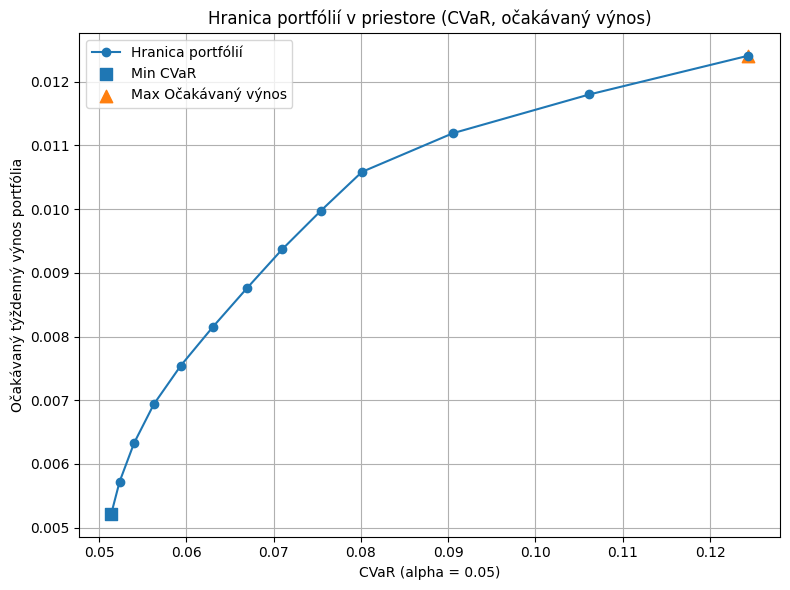

In [6]:
# --- 5. Grafická hranica portfólií ---

plt.figure(figsize=(8, 6))

# spojnicový graf hranice (portfóliá zoradené podľa CVaR)
plt.plot(CVaR_zoznam, ExpReturn_zoznam, marker='o', linestyle='-', label='Hranica portfólií')

# zvýraznenie portfólia s minimálnym CVaR a max. výnosom
idx_min_CVaR = int(np.argmin(CVaR_zoznam))
idx_max_Exp  = int(np.argmax(ExpReturn_zoznam))

plt.scatter(CVaR_zoznam[idx_min_CVaR], ExpReturn_zoznam[idx_min_CVaR],
            marker='s', s=80, label='Min CVaR')
plt.scatter(CVaR_zoznam[idx_max_Exp], ExpReturn_zoznam[idx_max_Exp],
            marker='^', s=80, label='Max Očakávaný výnos')

plt.xlabel('CVaR (alpha = 0.05)')
plt.ylabel('Očakávaný týždenný výnos portfólia')
plt.title('Hranica portfólií v priestore (CVaR, očakávaný výnos)')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


Spojnicová krivka predstavuje hranicu portfólií, t. j. všetky portfóliá, ktoré algoritmus vypočítal pri postupnej zmene cieľového výnosu Ep. Krivka má prirodzene rastúci charakter: vyšší očakávaný výnos je spojený s vyšším rizikom CVaR. Štvorec označuje portfólio s najnižším rizikom CVaR. Trojuholník reprezentuje portfólio, ktoré dosiahlo najvyšší možný výnos, no zároveň nesie aj najvyššie riziko CVaR.

## Model výberu portfólia v priestore očakávaných výnosov a miery rizika MaxDD

Cieľom tejto časti projektu je nájsť portfóliá, ktoré minimalizujú maximálny pokles hodnoty investície (MaxDD), pri splnení požadovaného očakávaného výnosu portfólia. MaxDD je významným rizikovým ukazovateľom pre investorov, ktorí chcú obmedziť najväčší historický prepad hodnoty svojho kapitálu. Hľadáme teda najkonzervatívnejšie portfóliá na tzv. efektívnej hranici v priestore (očakávaný výnos – MaxDD).


In [7]:
# ---------------------------------------------
#  Predpríprava pre MaxDD – kumulatívne výnosy
# ---------------------------------------------
# kumulatívne (súčtové) výnosy pre každý čas t a akciu j:
# cumsum_r[t, j] = sum_{k=0}^t r_{k,j}
cumsum_r = np.cumsum(vstup, axis=0)

# ---------------------------------------------
# 4. Výpočet 20 portfólií na MaxDD hranici
# ---------------------------------------------
Ep_list       = []
ExpReturn_list = []
MaxDD_list    = []
W_list        = []

for i in range(20):
    # 20 cieľových úrovní očakávaného výnosu
    Ep = Epmin + (Epmax - Epmin) * i / 19
    Ep_list.append(Ep)

    m = Model()  # default = minimize

    # váhy portfólia
    w = [m.add_var(name=f"w_{j}", var_type="C", lb=0) for j in N]

    # premenné pre cestu portfólia a drawdown
    V = [m.add_var(name=f"V_{t}", var_type="C") for t in T]   # "bohatstvo" v čase t
    U = [m.add_var(name=f"U_{t}", var_type="C") for t in T]   # historické maximum
    D = [m.add_var(name=f"D_{t}", var_type="C") for t in T]   # drawdown v čase t
    MaxDD = m.add_var(name="MaxDD", var_type="C")             # maximálny drawdown

    # 4.1. Vzťahy pre vývoj portfólia
    for t in T:
        # V_t = 1 + sum_j ( sum_{k<=t} r_{k,j} ) * w_j
        m += V[t] == 1 + xsum(float(cumsum_r[t, j]) * w[j] for j in N)

    # 4.2. Historické maximum U_t
    for t in T:
        m += U[t] >= V[t]
        if t > 0:
            m += U[t] >= U[t-1]
        else:
            # na začiatku aspoň 1
            m += U[t] >= 1

    # 4.3. Drawdown D_t a MaxDD
    for t in T:
        m += D[t] >= U[t] - V[t]
        m += MaxDD >= D[t]

    # 4.4. Obmedzenie na očakávaný výnos portfólia
    m += xsum(E[j] * w[j] for j in N) >= Ep

    # 4.5. Súčet váh = 1 (long-only)
    m += xsum(w[j] for j in N) == 1

    # 4.6. Cieľ: minimalizovať MaxDD
    m.objective = minimize(MaxDD)

    # optimalizácia
    m.optimize()

    vahy = np.array([w[j].x for j in N])

    ExpReturn = float(sum(E[j] * vahy[j] for j in N))
    MaxDD_value = float(MaxDD.x)

    ExpReturn_list.append(ExpReturn)
    MaxDD_list.append(MaxDD_value)
    W_list.append(vahy)


### Výsledné portfóliá (MaxDD)
Uvedená tabuľka zobrazuje 20 portfolií získaných pomocou optimalizačného modelu. Každý riadok tabulky predstavuje jedno portfólio,
určené pre konkrétnu úroveň cieľového očakávaného výnosu \(Ep\).
Súčasťou tabuľky je:

- požadovaný cieľový výnos,
- skutočne dosiahnutý očakávaný výnos,
- vypočítaná hodnota MaxDD,
- váhy jednotlivých akcií v portfóliu.

In [8]:
# ---------------------------------------------
# 5. Prehľadná tabuľka portfólií (MaxDD)
# ---------------------------------------------
tab_maxdd = pd.DataFrame({
    "ID_portfolia": range(1, len(Ep_list)+1),
    "Ep": Ep_list,
    "ExpReturn": ExpReturn_list,
    "MaxDD": MaxDD_list
})

for idx, ticker in enumerate(tickers):
    tab_maxdd[f"w_{ticker}"] = [W_list[i][idx] for i in range(len(W_list))]

tab_maxdd["Ep"] = tab_maxdd["Ep"].round(6)
tab_maxdd["ExpReturn"] = tab_maxdd["ExpReturn"].round(6)
tab_maxdd["MaxDD"] = tab_maxdd["MaxDD"].round(6)

for ticker in tickers:
    tab_maxdd[f"w_{ticker}"] = tab_maxdd[f"w_{ticker}"].round(4)

print("\nTabuľka portfólií – model MaxDD:")
print(tab_maxdd)


Tabuľka portfólií – model MaxDD:
    ID_portfolia        Ep  ExpReturn     MaxDD  w_NVDA  w_MSFT  w_AAPL  \
0              1  0.000859   0.003976  0.257255  0.7998     0.0  0.0000   
1              2  0.001467   0.003976  0.257255  0.7998     0.0  0.0000   
2              3  0.002075   0.003976  0.257255  0.7998     0.0  0.0000   
3              4  0.002683   0.003976  0.257255  0.7998     0.0  0.0000   
4              5  0.003290   0.003976  0.257255  0.7998     0.0  0.0000   
5              6  0.003898   0.003976  0.257255  0.7998     0.0  0.0000   
6              7  0.004506   0.004506  0.261558  0.6988     0.0  0.0554   
7              8  0.005114   0.005114  0.269271  0.5794     0.0  0.1243   
8              9  0.005722   0.005722  0.277018  0.4627     0.0  0.1891   
9             10  0.006329   0.006329  0.284934  0.3598     0.0  0.2337   
10            11  0.006937   0.006937  0.293021  0.2708     0.0  0.2577   
11            12  0.007545   0.007545  0.301262  0.1838     0.0  0

### Interpretácia výsledných portfólií (MaxDD)

Z tabuľky portfólií pre model MaxDD vidno, ako sa pri raste cieľového výnosu \(Ep\) mení
zloženie portfólia aj úroveň rizika meraného maximálnym drawdownom.

 **Portfólio s minimálnym rizikom (ID 1–5)**  
  Pre prvých päť portfólií je hodnota MaxDD rovnaká, približne $0{,}2573$, a zároveň
  očakávaný výnos portfólia je $ \text{ExpReturn} \approx 0{,}00398 $.  
  Tieto portfóliá majú identické váhy:
  dominantná je akcia **NVDA** (≈ 80 %), doplnená akciami **GOOGL** (≈ 12,9 %) a
  **AMZN** (≈ 7,2 %). Ide o najkonzervatívnejšie riešenie v rámci modelu.


 **Portfólio s maximálnym očakávaným výnosom (ID 20)**  
  Posledné portfólio má najvyšší očakávaný výnos
  $ \text{ExpReturn} \approx 0{,}01241 $, avšak dosahuje najvyšší
  MaxDD ≈ $0{,}9425$. Portfólio je koncentrované do akcie **FDX**. 
  Ponúka najvyšší výnos, ale aj výrazne najväčší potenciálny prepad hodnoty.

 **Vybrané portfólio (ID 13)**  
- očakávaný výnos: $ \text{ExpReturn} \approx 0.00815 $
- maximálny drawdown: $ \text{MaxDD} \approx 0.3153 $
- rozumná miera diverzifikácie medzi akcie (AAPL, NVDA, GOOGL, AMZN)
- ponúka vyšší výnos ako najkonzervatívnejšie portfóliá,
- zachováva prijateľnú úroveň rizika - nie je koncentrované do jednej akcie





### Graf efektívnej hranice portfólií (MaxDD – očakávaný výnos)

Nasledujúci graf zobrazuje efektívnu hranicu portfólií v priestore
riziko merané MaxDD a očakávaný týždenný výnos. 

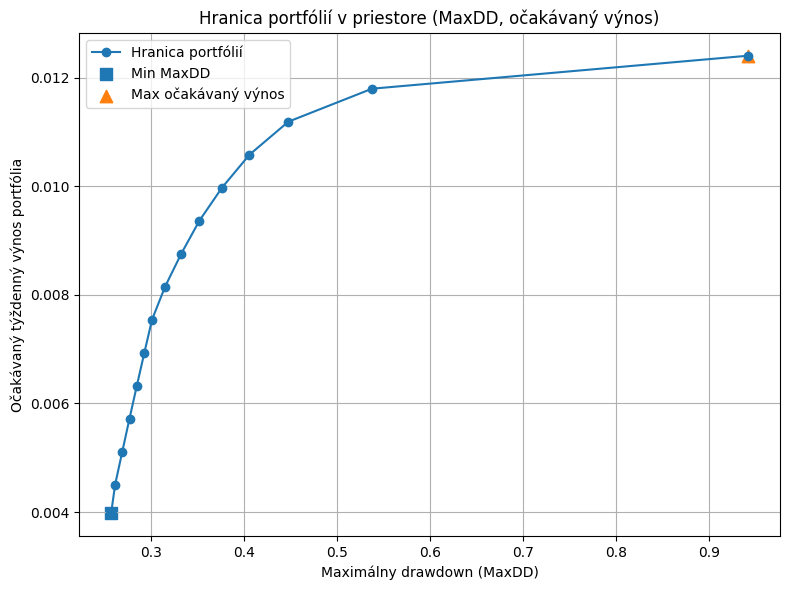

In [9]:
# ---------------------------------------------
# 6. Graf MaxDD–výnos (hranica portfólií)
# ---------------------------------------------
plt.figure(figsize=(8, 6))

plt.plot(MaxDD_list, ExpReturn_list, marker="o", linestyle="-", label="Hranica portfólií")

idx_min_MaxDD = int(np.argmin(MaxDD_list))
idx_max_Exp   = int(np.argmax(ExpReturn_list))

plt.scatter(MaxDD_list[idx_min_MaxDD], ExpReturn_list[idx_min_MaxDD],
            marker="s", s=80, label="Min MaxDD")
plt.scatter(MaxDD_list[idx_max_Exp], ExpReturn_list[idx_max_Exp],
            marker="^", s=80, label="Max očakávaný výnos")

plt.xlabel("Maximálny drawdown (MaxDD)")
plt.ylabel("Očakávaný týždenný výnos portfólia")
plt.title("Hranica portfólií v priestore (MaxDD, očakávaný výnos)")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


Z grafu je zreteľné, že medzi očakávaným výnosom portfólia a rizikom meraným
maximálnym drawdownom existuje pozitívny vzťah. Čím vyšší očakávaný výnos
portfólia investor požaduje, tým väčší maximálny historický pokles hodnoty
(MaxDD) musí akceptovať.

Na ľavej časti krivky sa nachádzajú najbezpečnejšie portfóliá s nízkou hodnotou
MaxDD a nižším očakávaným výnosom. Tieto riešenia sú vhodné pre veľmi
konzervatívnych investorov, ktorí kladú dôraz predovšetkým na stabilitu a
ochranu kapitálu.

S posunom po krivke doprava rastie očakávaný výnos portfólia, ale súčasne aj jeho
riziko – maximálny drawdown sa zvyšuje. Na pravom konci hranice sa nachádza
portfólio s najvyšším dosiahnutým výnosom, ktoré je však spojené aj s
najväčším možným prepadom hodnoty investície.


In [24]:
# --- Definícia mojich váh ---
w_custom = np.array([
    0.15, 0.13, 0.13, 0.10, 0.10,
    0.09, 0.08, 0.08, 0.07, 0.07
])

# Funkcia iba pre modelové čísla (z CVaR modelu)
def model_stats(w):
    model_mean = float(np.mean(vstup @ w))

    # CVaR zo strát (historicky)
    losses = -(vstup @ w)
    losses_sorted = np.sort(losses)[::-1]
    k = max(1, int(np.floor(0.05 * len(losses_sorted))))
    model_cvar = float(losses_sorted[:k].mean())

    return model_mean, model_cvar

# Indexy efektívnych portfólií
idx_min_CVaR = int(np.argmin(CVaR_zoznam))
idx_max_Exp  = int(np.argmax(ExpReturn_zoznam))

w_minCvar = np.array(W_zoznam[idx_min_CVaR])
w_maxExp  = np.array(W_zoznam[idx_max_Exp])

# --- Analýza 3 portfólií ---
data = {
    "Nazov": [
        "Efektívne – Min CVaR",
        "Moje portfólio",
        "Efektívne – Max výnos"
    ],
    "ExpReturn": [
        model_stats(w_minCvar)[0],
        model_stats(w_custom)[0],
        model_stats(w_maxExp)[0]
    ],
    "CVaR": [
        model_stats(w_minCvar)[1],
        model_stats(w_custom)[1],
        model_stats(w_maxExp)[1]
    ],
}

# Pridanie váh do tabuľky
for idx, ticker in enumerate(tickers):
    data[f"w_{ticker}"] = [
        w_minCvar[idx],
        w_custom[idx],
        w_maxExp[idx]
    ]

df_compare_weights = pd.DataFrame(data)

# Zaokrúhlenie pre krajší výstup
df_compare_weights = df_compare_weights.round({
    "ExpReturn": 6, "CVaR": 6,
    **{f"w_{ticker}": 4 for ticker in tickers}
})

print("\nPorovnanie portfólií podľa modelu (CVaR):")
print(df_compare_weights)



Porovnanie portfólií podľa modelu (CVaR):
                   Nazov  ExpReturn      CVaR  w_NVDA  w_MSFT  w_AAPL  \
0   Efektívne – Min CVaR   0.005217  0.051451  0.0564    0.00  0.0706   
1         Moje portfólio   0.005615  0.066632  0.1500    0.13  0.1300   
2  Efektívne – Max výnos   0.012407  0.124497  0.0000    0.00  0.0000   

   w_GOOGL  w_AMZN  w_ANET  w_GE   w_JPM  w_INTC  w_FDX  
0      0.0     0.0  0.1414  0.00  0.2192  0.5124   0.00  
1      0.1     0.1  0.0900  0.08  0.0800  0.0700   0.07  
2      0.0     0.0  0.0000  0.00  0.0000  0.0000   1.00  


### Porovnanie môjho portfólia s efektívnymi portfóliami (model CVaR)

V tejto časti porovnávam moje navrhnuté portfólio s dvoma referenčnými
portfóliami odvodenými z efektívnej hranice modelu CVaR, a to s portfóliom s minimálnym rizikom a portfóliom s maximálnym výnosom. 

Moje portfólio má nasledovné váhy:

| Akcia | Váha |
|------|------|
| NVDA | 15 % |
| MSFT | 13 % |
| AAPL | 13 % |
| GOOGL | 10 % |
| AMZN | 10 % |
| ANET | 9 % |
| GE   | 8 % |
| JPM  | 8 % |
| INTC | 7 % |
| FDX  | 7 % |




In [31]:
# --- Definícia mojich váh ---
w_custom = np.array([
    0.15, 0.13, 0.13, 0.10, 0.10,
    0.09, 0.08, 0.08, 0.07, 0.07
])



alpha = 0.05  # hladina pre CVaR (rovnaká ako v modeli)

def compute_model_stats_cvar_same_as_model(w_port):

    r_p = vstup @ w_port   # t-dim vektor výnosov portfólia
    model_mean = float(np.mean(r_p))
    m = Model()
    T_idx = range(len(r_p))
    z = [m.add_var(lb=0, name=f"z_{t}") for t in T_idx]
    VaR = m.add_var(name="VaR")
    m.objective = minimize(VaR + xsum(z[t] for t in T_idx) / (alpha * len(r_p)))
    for t in T_idx:
        m += z[t] + float(r_p[t]) + VaR >= 0
    m.optimize()
    model_cvar = float(m.objective_value) 

    return model_mean, model_cvar

model_mean_custom, model_cvar_custom = compute_model_stats_cvar_same_as_model(w_custom)

# Indexy efektívnych portfólií
idx_min_CVaR = int(np.argmin(CVaR_zoznam))
idx_max_Exp  = int(np.argmax(ExpReturn_zoznam))
idx_i = 13

w_minCvar = np.array(W_zoznam[idx_min_CVaR])
w_maxExp  = np.array(W_zoznam[idx_max_Exp])
w_i = np.array(W_zoznam[idx_i])

# --- Analýza 3 portfólií ---
data = {
    "Nazov": [
        "Efektívne – Min CVaR(ID 1-8)",
        "Moje portfólio",
        "Vybrané portfólio(ID 13)",
        "Efektívne – Max výnos(ID 20)"
    ],
    "ExpReturn": [
        model_stats(w_minCvar)[0],
        model_stats(w_custom)[0],
        model_stats(w_i)[0],
        model_stats(w_maxExp)[0]
    ],
    "CVaR": [
        model_stats(w_minCvar)[1],
        model_stats(w_custom)[1],
        model_stats(w_i)[1],
        model_stats(w_maxExp)[1]
    ],
}

# Pridanie váh do tabuľky
for idx, ticker in enumerate(tickers):
    data[f"w_{ticker}"] = [
        w_minCvar[idx],
        w_custom[idx],
        w_i[idx],
        w_maxExp[idx]
    ]

df_compare_weights = pd.DataFrame(data)

df_compare_weights = df_compare_weights.round({
    "ExpReturn": 6, "CVaR": 6,
    **{f"w_{ticker}": 4 for ticker in tickers}
})

print("\nPorovnanie portfólií podľa modelu (CVaR):")
print(df_compare_weights)



Porovnanie portfólií podľa modelu (CVaR):
                          Nazov  ExpReturn      CVaR  w_NVDA  w_MSFT  w_AAPL  \
0  Efektívne – Min CVaR(ID 1-8)   0.005217  0.051451  0.0564    0.00  0.0706   
1                Moje portfólio   0.005615  0.066632  0.1500    0.13  0.1300   
2      Vybrané portfólio(ID 13)   0.008760  0.067036  0.0000    0.00  0.3852   
3  Efektívne – Max výnos(ID 20)   0.012407  0.124497  0.0000    0.00  0.0000   

   w_GOOGL  w_AMZN  w_ANET  w_GE   w_JPM  w_INTC   w_FDX  
0      0.0  0.0000  0.1414  0.00  0.2192  0.5124  0.0000  
1      0.1  0.1000  0.0900  0.08  0.0800  0.0700  0.0700  
2      0.0  0.3228  0.0348  0.00  0.0000  0.2534  0.0037  
3      0.0  0.0000  0.0000  0.00  0.0000  0.0000  1.0000  


Tabuľka porovnáva moje vlastné portfólio s tromi referenčnými portfóliami
z efektívnej hranice modelu CVaR:

- **Efektívne – Min CVaR (ID 1–8)**: portfólio s najnižším rizikom (minimálny CVaR),
- **Vybrané portfólio z hranice (ID 13)**: portfólio s najlepším pomerom výnosu a rizika
- **Efektívne – Max výnos (ID 20)**: portfólio s najvyšším očakávaným výnosom.

**Moje portfólio** dosahuje očakávaný výnos ExpReturn = 0.005615, čo je mierne viac ako pri minimálnom CVaR portfóliu  0.005217, avšak pri vyššom riziku CVaR 0.066632 vs.  0.051451. Inak povedané porovnaní s Min CVaR portfóliom prináša o niečo vyšší výnos za cenu mierne zvýšeného rizika.
Na druhej strane, v porovnaní s portfóliom s maximálnym výnospm ExpReturn= 0.012407, CVaR 0.124497, je moje riešenie podstatne menej rizikové a zároveň diverzifikovanejšie.


Z porovnania vyplýva, že **moje portfólio** predstavuje mierne rastovejšiu
alternatívu k minimálne rizikovému portfóliu, zatiaľ čo **vybrané portfólio ID 13**
ponúka podstatne vyšší očakávaný výnos pri veľmi podobnej úrovni CVaR.
Ak by investor toleroval o niečo vyššie riziko, portfólio ID 13 by bolo
z hľadiska pomeru výnos/riziko atraktívnejšou voľbou než moje pôvodné portfólio,
pričom portfólio ID 20 ostáva skôr extrémnym. 